# Stichprobe im Strassenraum (ausserhalb der Kette)

**Ziel.** 30 zufällig gezogene Felder zeigen, die der Auftraggeber im Strassenraum **neu gesetzt** hat und bei denen **kein amtliches Objekt** in der Nähe liegt. Der Auftraggeber ordnet jedes Feld einer Art zu.

**Warum.** Im Vergleichsraum hat die Ground Truth mehr Felder als die amtlichen Daten (Notebook 10, Abschnitt 6: Teil 3 des Deltas). Solange offen ist, was das für Felder sind, lässt sich dieser Teil nicht deuten. Es können Felder sein, die in den amtlichen Daten fehlen, oder Felder, die nicht öffentlich sind. Die Stichprobe zeigt, was dort aufgemalt ist (`01b`, 10.3, Punkt 3, und Abschnitt 11.2, N3).

**Was die Stichprobe nicht kann.** Ob ein Feld rechtlich öffentlich ist, sieht man von oben nicht. Und 30 Felder geben nur grobe Anteile.

**Was sich nicht ändert.** Die Stichprobe betrifft die Ground Truth, nicht das Netz. Lösungsblatt und Ergebnisse bleiben, wie sie sind.

**Eingaben:** `kaestchen.gpkg` (Notebook 04), `ground_truth_hand.json` (nur gelesen), amtliche Daten (Strassenparkplätze 2021, DAV-Punkte, Parkstreifen), die Luftbilder beider Jahre.
**Ausgaben:** `ergebnisse/stichprobe_strassenraum.csv` (die gezogenen Felder), drei Bildblätter `ergebnisse/abbildungen/stichprobe_strassenraum_1.jpg` bis `_3.jpg`, und die Vorlage `daten/ground_truth/stichprobe_strassenraum_urteil.csv` (nur wenn es sie noch nicht gibt).

In [1]:
import json                        # Einstellungen und die Datei des Auftraggebers lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen
HAND = ROOT / "daten" / "ground_truth" / "ground_truth_hand.json"                   # die Arbeit des Auftraggebers (wird nur gelesen)
URTEILE = ROOT / "daten" / "ground_truth" / "stichprobe_strassenraum_urteil.csv"    # hier trägt der Auftraggeber seine Urteile ein

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
CRS, SEED, VERSUCHE = EINST["CRS"], EINST["SEED"], EINST["VERSUCHE"]

import numpy as np                 # Rechnen mit Zahlenblöcken
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
import rasterio                    # Luftbilder lesen
from rasterio.merge import merge   # Ausschnitt aus mehreren Bilddateien zusammensetzen
from scipy.spatial import cKDTree  # findet zu jedem Punkt schnell den nächsten Nachbarn
from matplotlib_inline.backend_inline import set_matplotlib_formats   # Format der Abbildungen im Notebook

set_matplotlib_formats("jpeg", pil_kwargs={"quality": 88})           # Luftbilder als JPEG einbetten: so bleibt das Notebook klein
print("Einstellungen: CRS =", CRS, "| Seed =", SEED)

Einstellungen: CRS = EPSG:2056 | Seed = 42


**Einstellungen dieses Schritts** (vor dem Ziehen festgelegt, `01b`, Abschnitt 11.2, N3):

| Einstellung | Wert | Warum |
| --- | --- | --- |
| `NAH_M` | 3 m | "in der Nähe" wie in `ground_truth_pruefen`: etwa eine halbe Feldlänge |
| `ANZAHL` | 30 | Grösse der Stichprobe (`01b`, 10.3) |
| `HALB_M` | 10 m | jedes Bild zeigt 20 × 20 m um das Feld |

In [2]:
NAH_M = 3.0
ANZAHL = 30
HALB_M = 10.0

## 1. Welche Felder kommen in Frage?

**Schritt 1: neu gesetzte Felder im Strassenraum.** Aus allen gesetzten Feldern (Notebook 04) bleiben die, die
- der Auftraggeber **neu** gesetzt hat (nicht aus einem DAV-Vorschlag übernommen),
- im **Strassenraum** liegen (Regel B: Das Grundstück besteht mindestens zur Hälfte aus Strassenraum; `01b`, Abschnitt 11, E2),
- im Gebiet liegen und nicht in einem Kontroll-Ausschnitt (dort wurden DAV-Felder absichtlich neu gesetzt).

Vorher: alle gesetzten Felder → nachher: neu gesetzte Felder im Strassenraum.

In [3]:
felder = gpd.read_file(VERARB / "kaestchen.gpkg", ignore_geometry=True)        # alle gesetzten Felder (Notebook 04)
ausschnitte = json.loads(HAND.read_text(encoding="utf-8"))["kacheln"]          # Liste der Ausschnitte aus dem Werkzeug
kontroll = {ausschnitt["id"] for ausschnitt in ausschnitte if ausschnitt["blind"]}   # Kennungen der Kontroll-Ausschnitte
gebiet = gpd.read_file(VERARB / "gebiet.geojson").geometry.iloc[0]             # Fläche des Gebiets (Notebook 00)
im_gebiet = gpd.GeoSeries(gpd.points_from_xy(felder.x, felder.y), crs=CRS, index=felder.index).within(gebiet)

neu = felder[(felder.herkunft == "neu") & felder.strassenraum & im_gebiet & ~felder.kachel.isin(kontroll)].copy()
print(f"Vorher: {len(felder)} gesetzte Felder → nachher: {len(neu)} neu gesetzte Felder im Strassenraum")

Vorher: 3269 gesetzte Felder → nachher: 624 neu gesetzte Felder im Strassenraum


**Schritt 2: Liegt ein amtliches Objekt in der Nähe?** Dieselbe Probe wie in `ground_truth_pruefen`, Abschnitt 6: Für jedes Feld messen wir den Abstand zum nächsten Objekt aus drei amtlichen Ebenen.

| Ebene | Inhalt |
| --- | --- |
| Strassenparkplätze der Stadt, Stand 31.12.2021 | ein Punkt je Platz |
| DAV-Punkte, Stand 2025 | ein Punkt je Feld |
| Parkstreifen der DAV, Stand 2025 | Linien, zum Beispiel Blaue Zone und Güterumschlag |

`cKDTree(...).query(...)` gibt zu jedem Feld den Abstand zum nächsten Punkt; `distance` den Abstand zur nächsten Linie.

Vorher: neu gesetzte Felder im Strassenraum → nachher: dieselben Felder mit der Angabe "amtliches Objekt in 3 m: ja oder nein".

In [4]:
plaetze_2021 = gpd.read_file(ROH / "parkplaetze/Strassenparkplaetze_OGD_2021_view_pp_ogd.geojson").to_crs(CRS).explode(index_parts=False)
dav_punkte = gpd.read_file(VERARB / "dav_punkte.gpkg")                         # DAV-Punkte (Notebook 01)
streifen = gpd.read_file(ROH / "parkplaetze/DAV_oeff_strassenparkierung_dav_l.geojson").to_crs(CRS).explode(index_parts=False)   # Parkstreifen als einzelne Linien

lage = np.column_stack([neu.x, neu.y])                                         # x und y als Zahlenblock
abstand_2021, _ = cKDTree(np.column_stack([plaetze_2021.geometry.x, plaetze_2021.geometry.y])).query(lage)   # nächster Platz 2021
abstand_dav, _ = cKDTree(np.column_stack([dav_punkte.geometry.x, dav_punkte.geometry.y])).query(lage)         # nächster DAV-Punkt
abstand_streifen = gpd.GeoSeries(gpd.points_from_xy(neu.x, neu.y), crs=CRS).distance(streifen.union_all()).values   # nächster Parkstreifen
neu["amtlich_nah"] = (abstand_2021 <= NAH_M) | (abstand_dav <= NAH_M) | (abstand_streifen <= NAH_M)

ohne = neu[~neu.amtlich_nah]                                                   # Maske: nichts Amtliches in 3 m
print(f"Vorher: {len(neu)} Felder → mit amtlichem Objekt in 3 m: {int(neu.amtlich_nah.sum())} | ohne: {len(ohne)}")
ohne.form.value_counts().rename("Felder ohne amtliches Objekt, nach Form").to_frame()

Vorher: 624 Felder → mit amtlichem Objekt in 3 m: 432 | ohne: 192


,"Felder ohne amtliches Objekt, nach Form"
form,
Einzelfeld,76
Streifen ohne Einzelfelder,65
gelbes Feld mit Kreuz,50
unklar,1


**Schritt 3: Streifen bleiben weg.** Die Form `Streifen ohne Einzelfelder` (`═`) steht für Linien und durchgezogene Bereiche. Sie zählen im Vergleich mit den amtlichen Daten nicht mit (`01b`, Abschnitt 11, E11) und gehören darum nicht in diese Stichprobe.

Vorher: Felder ohne amtliches Objekt → nachher: dieselben ohne Streifen. Aus ihnen wird gezogen.

In [5]:
kandidaten = ohne[ohne.form != "Streifen ohne Einzelfelder"]                   # Maske: alles ausser Streifen
print(f"Vorher: {len(ohne)} Felder → nachher: {len(kandidaten)} Felder, aus denen gezogen wird")
kandidaten.gruppe.value_counts().rename("davon in Blöcken der Gruppe").to_frame()

Vorher: 192 Felder → nachher: 127 Felder, aus denen gezogen wird


,davon in Blöcken der Gruppe
gruppe,
lernen,102
validieren,16
testen,9


## 2. 30 Felder ziehen

`sample(30, random_state=SEED)` zieht 30 Felder per Zufall. Mit dem festen Startwert kommt bei jedem Lauf dieselbe Auswahl heraus. Danach sortieren wir nach Ausschnitt, damit benachbarte Felder nebeneinanderstehen, und geben jedem Feld eine Nummer.

Vorher: alle Felder, die in Frage kommen → nachher: 30 nummerierte Felder.

In [6]:
stichprobe = kandidaten.sample(ANZAHL, random_state=SEED).sort_values(["kachel", "id"]).reset_index(drop=True)
stichprobe.insert(0, "nr", range(1, ANZAHL + 1))                               # Nummer 1 bis 30
spalten = ["nr", "id", "kachel", "form", "klasse", "kat_2021", "kat_2024_25", "x", "y"]
stichprobe[spalten].to_csv(ERG / "stichprobe_strassenraum.csv", index=False)
print(f"Vorher: {len(kandidaten)} Felder → nachher: {len(stichprobe)} gezogene Felder; gespeichert in ergebnisse/stichprobe_strassenraum.csv")
stichprobe[spalten].drop(columns=["x", "y"]).set_index("nr")

Vorher: 127 Felder → nachher: 30 gezogene Felder; gespeichert in ergebnisse/stichprobe_strassenraum.csv


,id,kachel,form,klasse,kat_2021,kat_2024_25
nr,,,,,,
1,neu_1795732456342_89,k_52395_24364,gelbes Feld mit Kreuz,weit,sichtbar,sichtbar
2,neu_1795736689134_697,k_52396_24366,gelbes Feld mit Kreuz,einzeln,einzeln,einzeln
3,neu_1795743765271_2011,k_52399_24363,unklar,weit,"verdeckt, belegt",sichtbar
4,neu_1795734118910_358,k_52401_24361,Einzelfeld,weit,kein Parkfeld,sichtbar
5,neu_1795734361997_396,k_52402_24360,Einzelfeld,weit,sichtbar,sichtbar
6,neu_1795734367766_397,k_52402_24360,Einzelfeld,weit,sichtbar,sichtbar
7,neu_1795734173083_363,k_52402_24361,Einzelfeld,weit,sichtbar,sichtbar
8,neu_1795734174503_364,k_52402_24361,Einzelfeld,weit,sichtbar,sichtbar
9,neu_1795744781804_2183,k_52403_24369,gelbes Feld mit Kreuz,einzeln,einzeln,kein Parkfeld


**Wie man die Tabelle liest.** `form` ist das Zeichen, das der Auftraggeber im Werkzeug gesetzt hat. `kat_2021` und `kat_2024_25` sagen, ob das Feld im jeweiligen Bild sichtbar ist. `kachel` ist der Ausschnitt; im Werkzeug lässt er sich mit `http://127.0.0.1:8765/?kachel=<Name>` öffnen.

## 3. Die Felder im Bild

**Schritt 1: einen Bildausschnitt lesen.** Wie in Notebook 08: `merge` setzt den verlangten Rahmen aus den Bilddateien zusammen, bei 5 cm je Pixel.

In [7]:
QUELLEN = {}                                                         # geöffnete Bilddateien je Versuch
for versuch, angaben in VERSUCHE.items():
    QUELLEN[versuch] = [rasterio.open(pfad) for pfad in sorted((ROH / "orthofoto" / angaben["ordner"]).glob("*.tif"))]

def lies_bild(versuch, x, y):
    # Bild von 2 × HALB_M Metern Seitenlänge um den Punkt (x, y): Rot, Grün, Blau
    bild, _ = merge(QUELLEN[versuch], bounds=(x - HALB_M, y - HALB_M, x + HALB_M, y + HALB_M), res=0.05, indexes=[1, 2, 3])
    return bild.transpose(1, 2, 0)                                   # (Farben, Zeilen, Spalten) -> (Zeilen, Spalten, Farben)

beispiel = stichprobe.iloc[0]
print("Feld Nr. 1:", lies_bild("A", beispiel.x, beispiel.y).shape, "= (Zeilen, Spalten, Farben)")

Feld Nr. 1: (400, 400, 3) = (Zeilen, Spalten, Farben)


**Schritt 2: ein Feld zeichnen.** Über das Bild kommen drei Arten von Zeichen:

| Zeichen | Bedeutung |
| --- | --- |
| grosser gelber Ring | das Feld, das beurteilt wird |
| kleine weisse Ringe | alle anderen gesetzten Felder in der Umgebung |
| hellblaues Kreuz, hellblaue Linie | amtliche Objekte **des jeweiligen Jahres**: links die Strassenparkplätze 2021, rechts die DAV-Punkte und Parkstreifen 2025 |

Beim beurteilten Feld selbst liegt kein amtliches Objekt in 3 m; in der Umgebung kann es welche geben.

In [8]:
AMTLICHE_PUNKTE = {"A": plaetze_2021, "B": dav_punkte}               # amtliche Punkte des jeweiligen Jahres
HELLBLAU = "#00e5ff"                                                 # hebt sich auf Luftbildern gut ab

def zeige_feld(ax, versuch, feld):
    # Zeichnet das Luftbild um ein Feld, die gesetzten Felder, die amtlichen Objekte und den gelben Ring
    links, rechts, unten, oben = feld.x - HALB_M, feld.x + HALB_M, feld.y - HALB_M, feld.y + HALB_M
    ax.imshow(lies_bild(versuch, feld.x, feld.y), extent=[links, rechts, unten, oben])
    nahe = felder[felder.x.between(links, rechts) & felder.y.between(unten, oben)]           # gesetzte Felder im Bild
    ax.plot(nahe.x, nahe.y, "o", markersize=8, markerfacecolor="none", markeredgecolor="white", markeredgewidth=1.3)
    amtlich = AMTLICHE_PUNKTE[versuch].cx[links:rechts, unten:oben]                          # amtliche Punkte im Bild
    ax.plot(amtlich.geometry.x, amtlich.geometry.y, "+", color=HELLBLAU, markersize=13, markeredgewidth=2.5)
    if versuch == "B":                                               # Parkstreifen gibt es nur im Stand 2025
        for linie in streifen.cx[links:rechts, unten:oben].geometry:
            ax.plot(*linie.xy, color=HELLBLAU, linewidth=2.5)
    ax.plot(feld.x, feld.y, "o", markersize=24, markerfacecolor="none", markeredgecolor="black", markeredgewidth=4.5)    # dunkler Rand für den Kontrast
    ax.plot(feld.x, feld.y, "o", markersize=24, markerfacecolor="none", markeredgecolor="#ffe600", markeredgewidth=2.5)  # der gelbe Ring
    ax.set_xlim(links, rechts); ax.set_ylim(unten, oben)
    ax.set_xticks([]); ax.set_yticks([])                             # keine Achsenbeschriftung

**Schritt 3: drei Blätter mit je 10 Feldern.** Je Feld zwei Bilder nebeneinander: links Frühjahr 2021, rechts Sommer 2024/25. In jeder Zeile stehen zwei Felder.

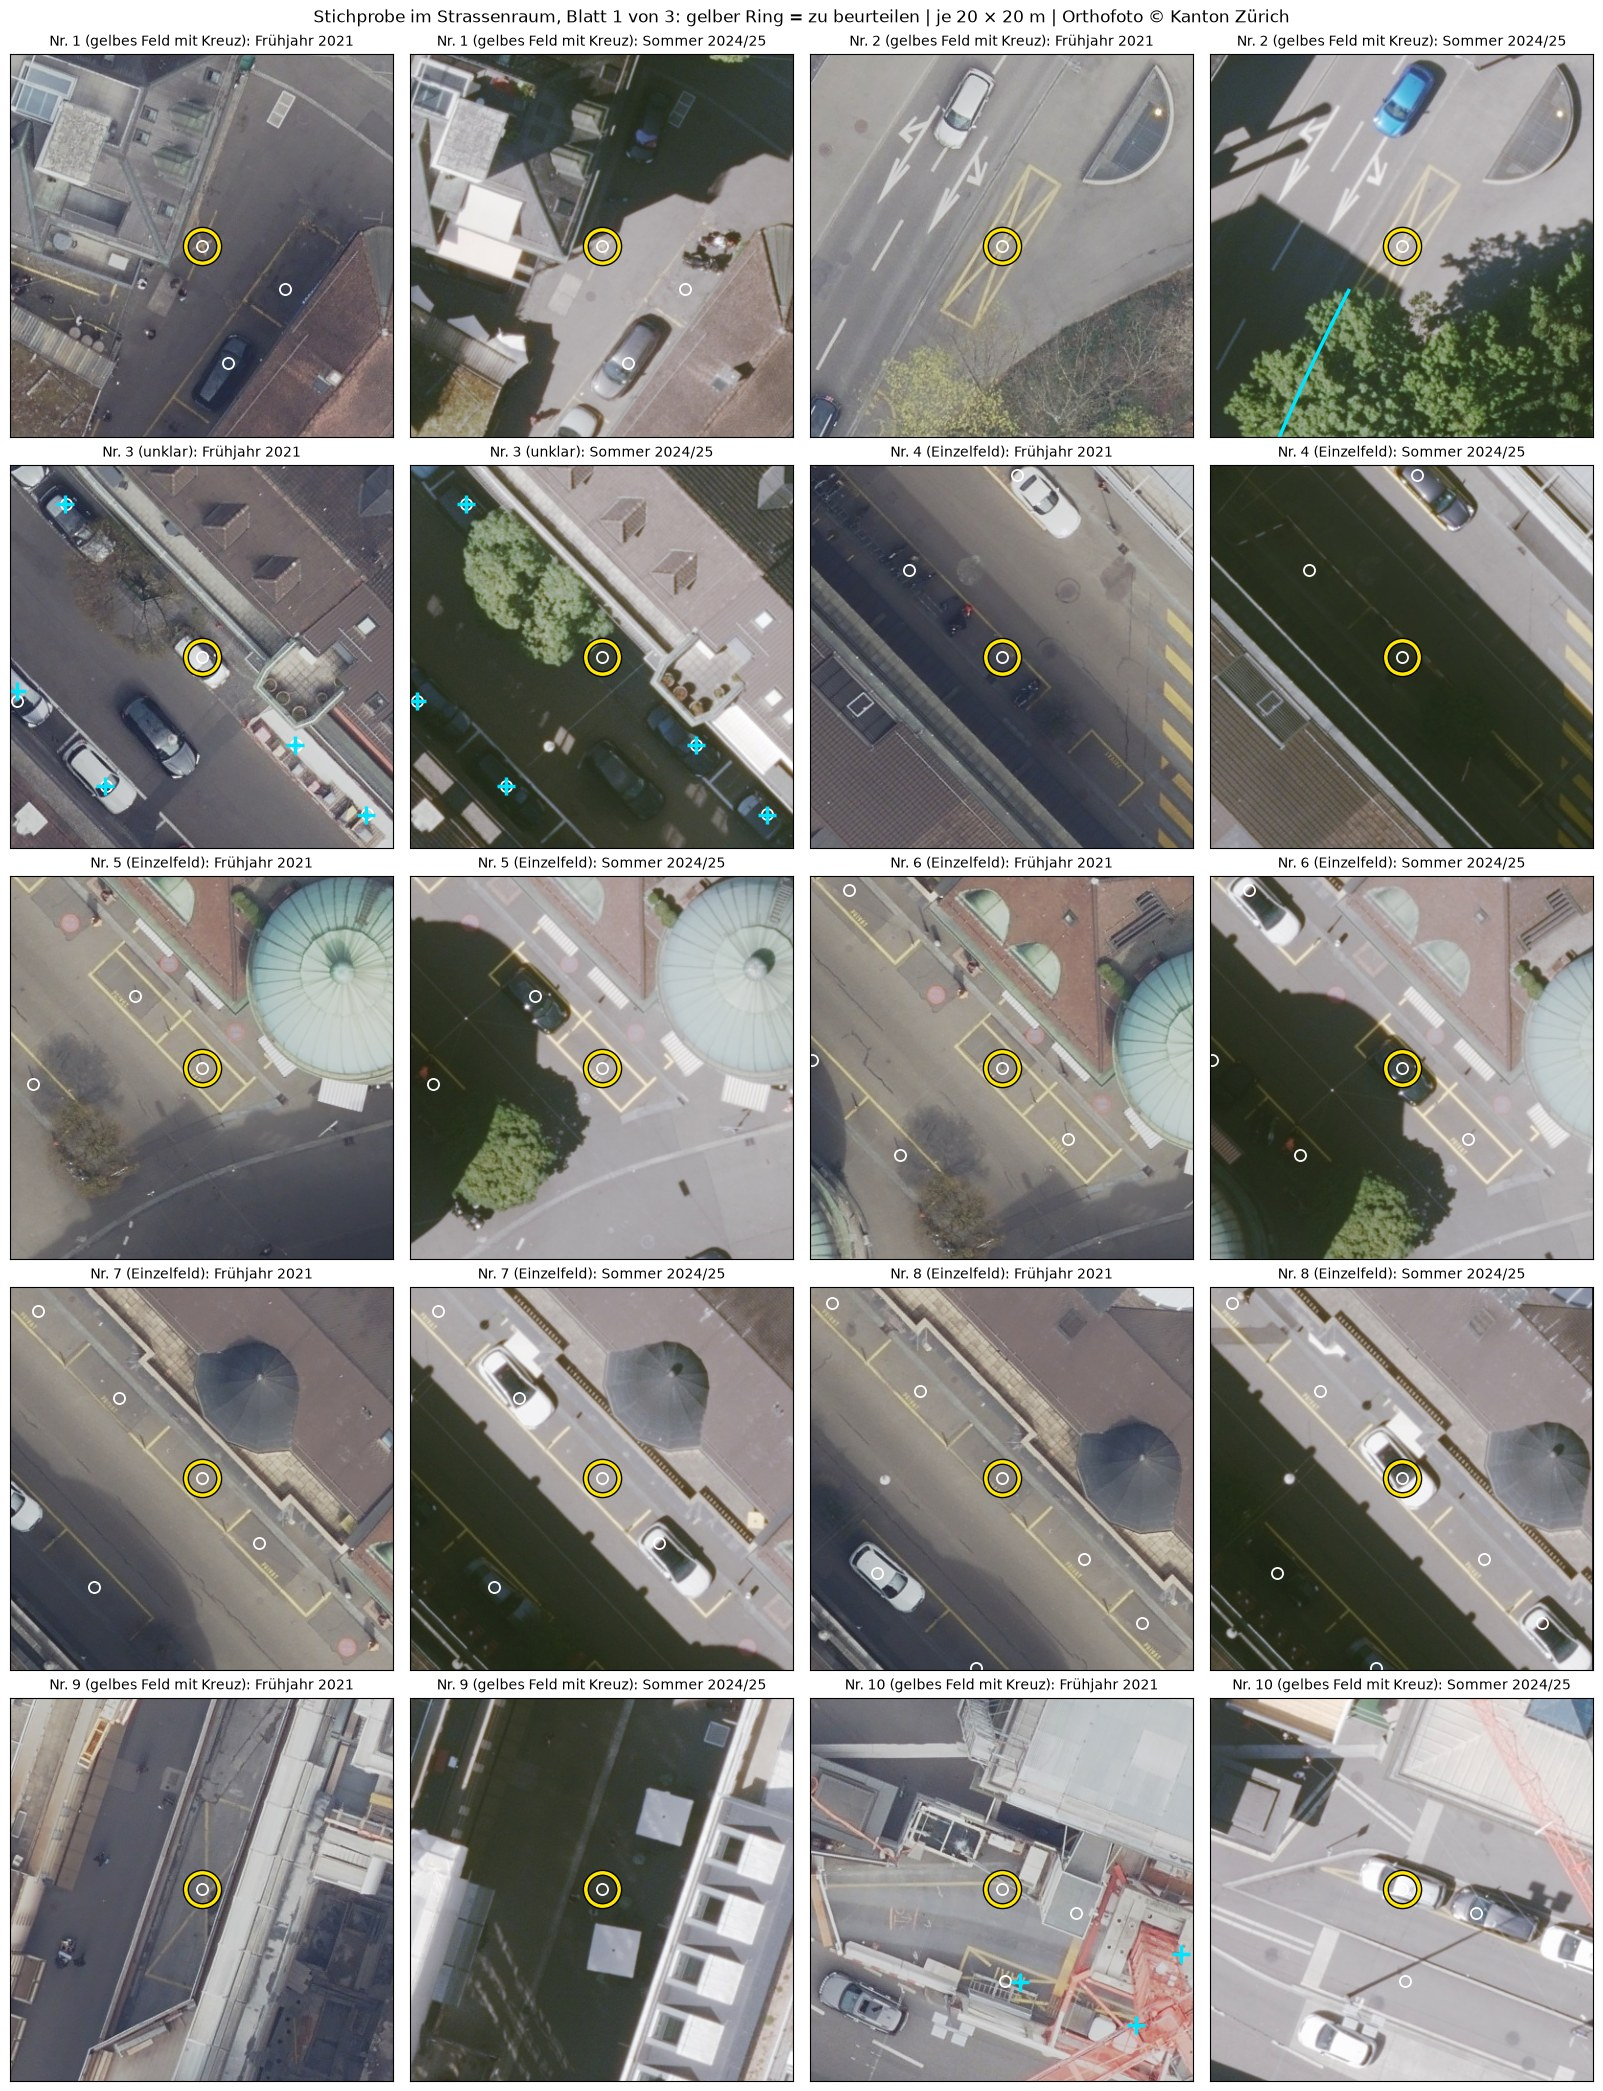

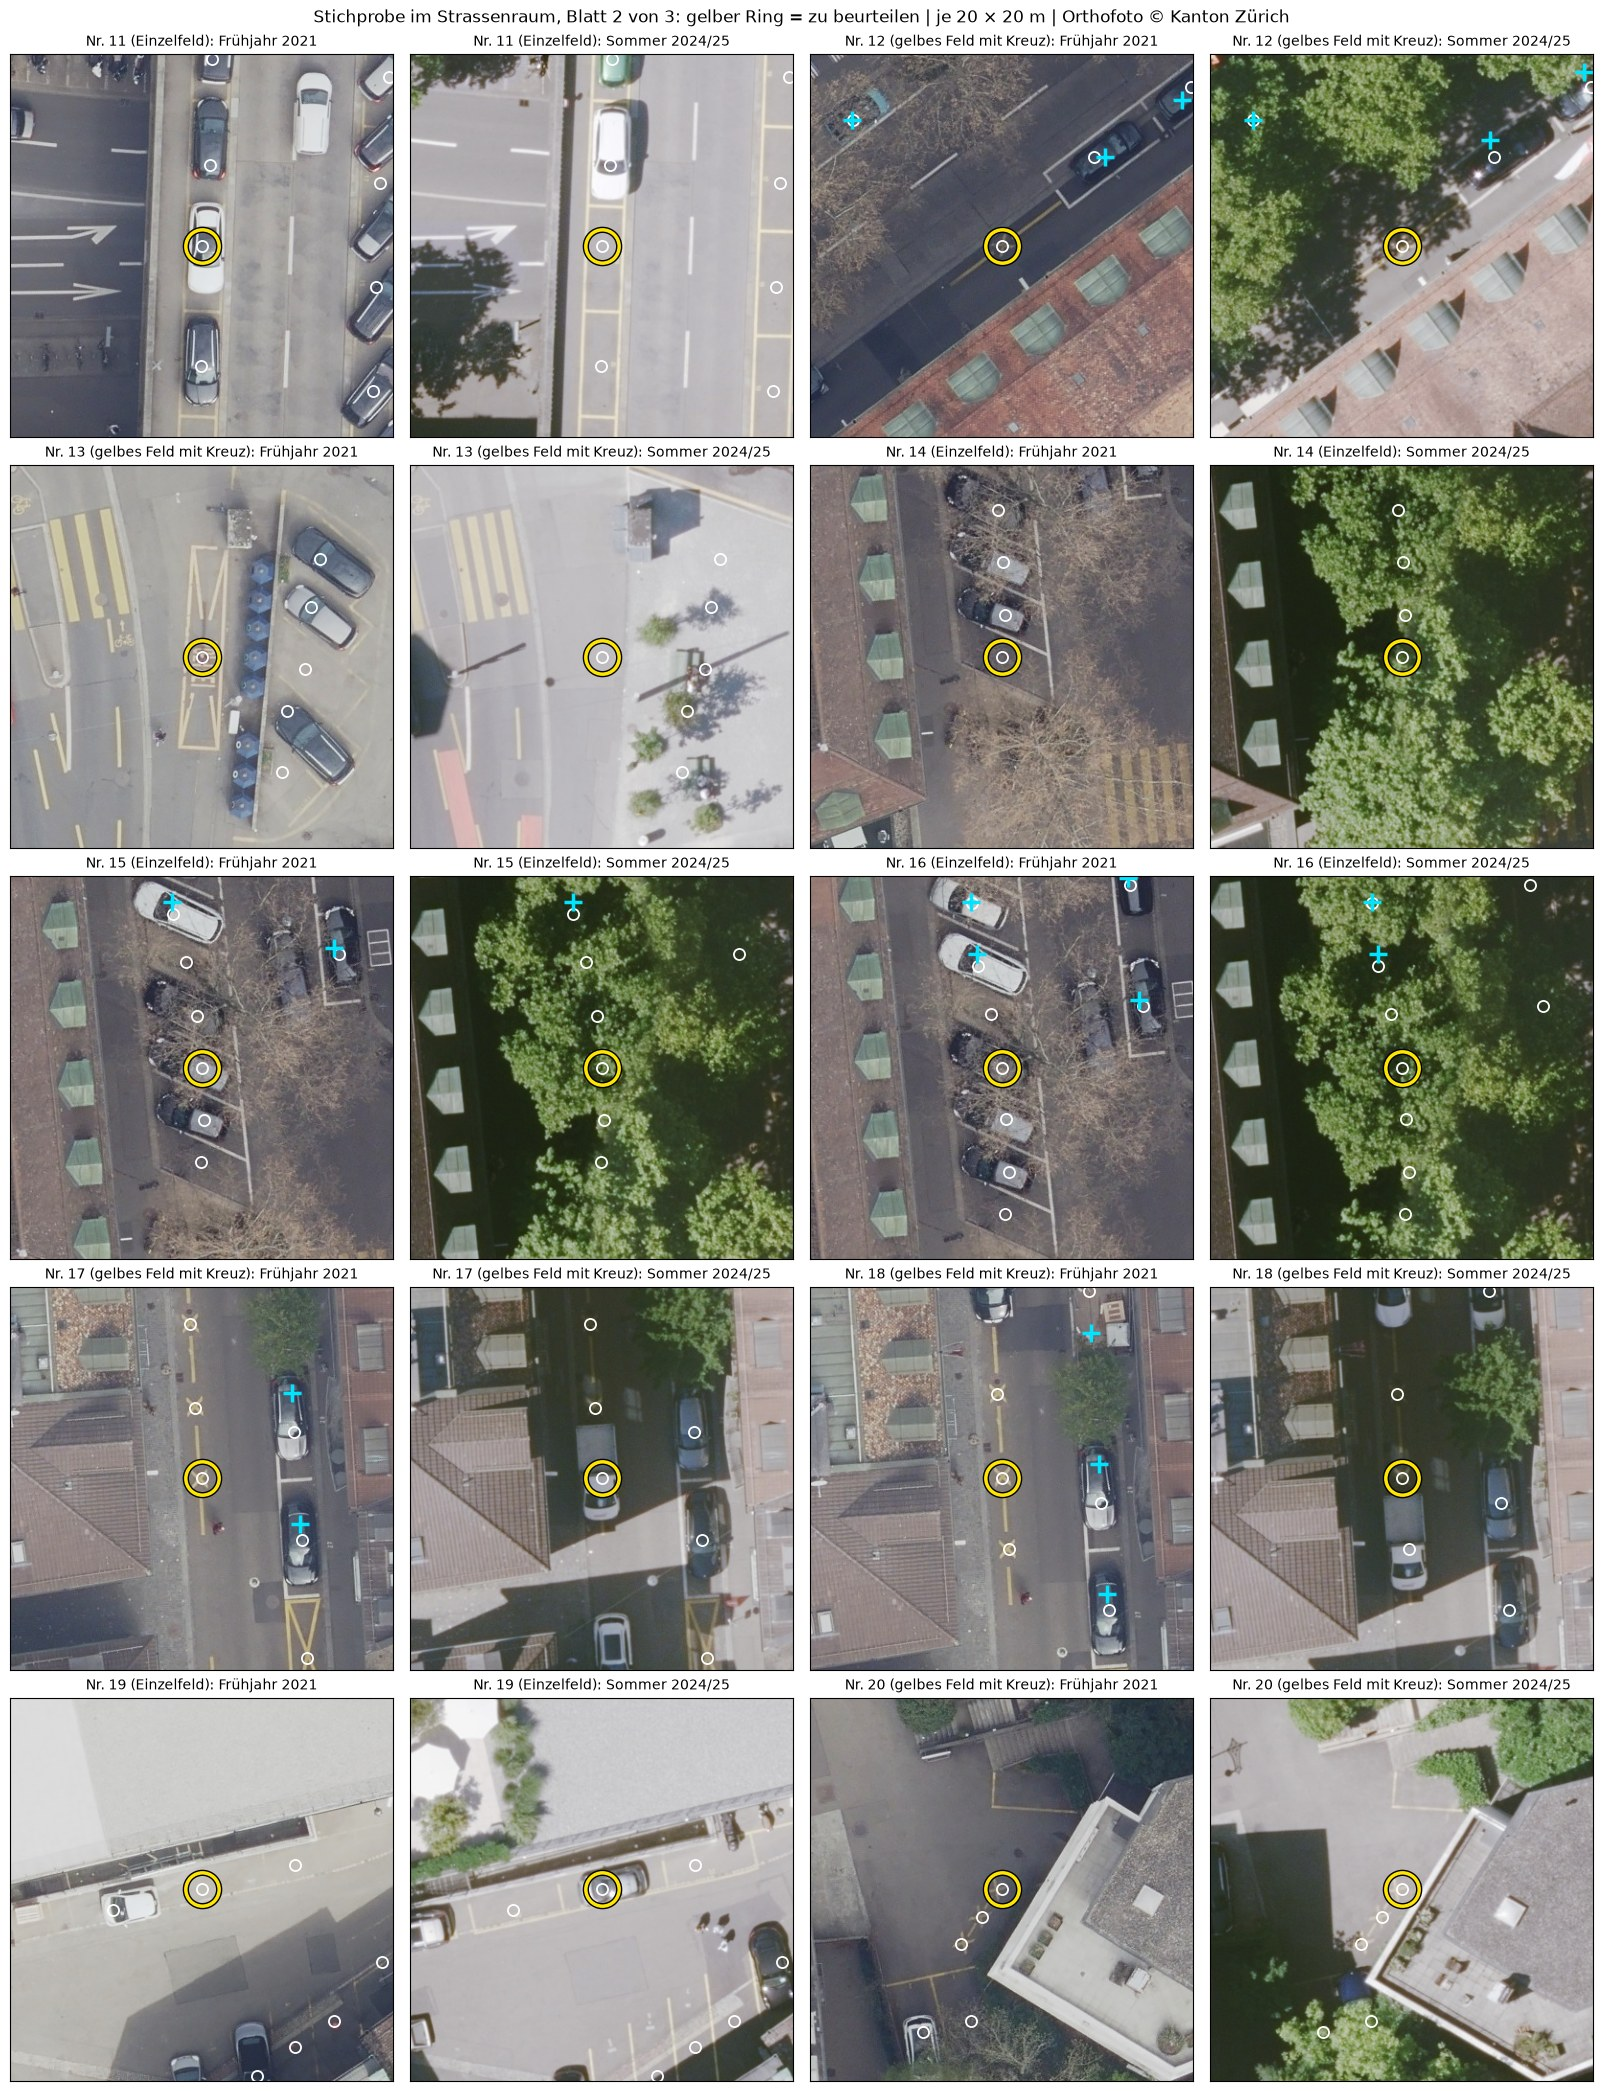

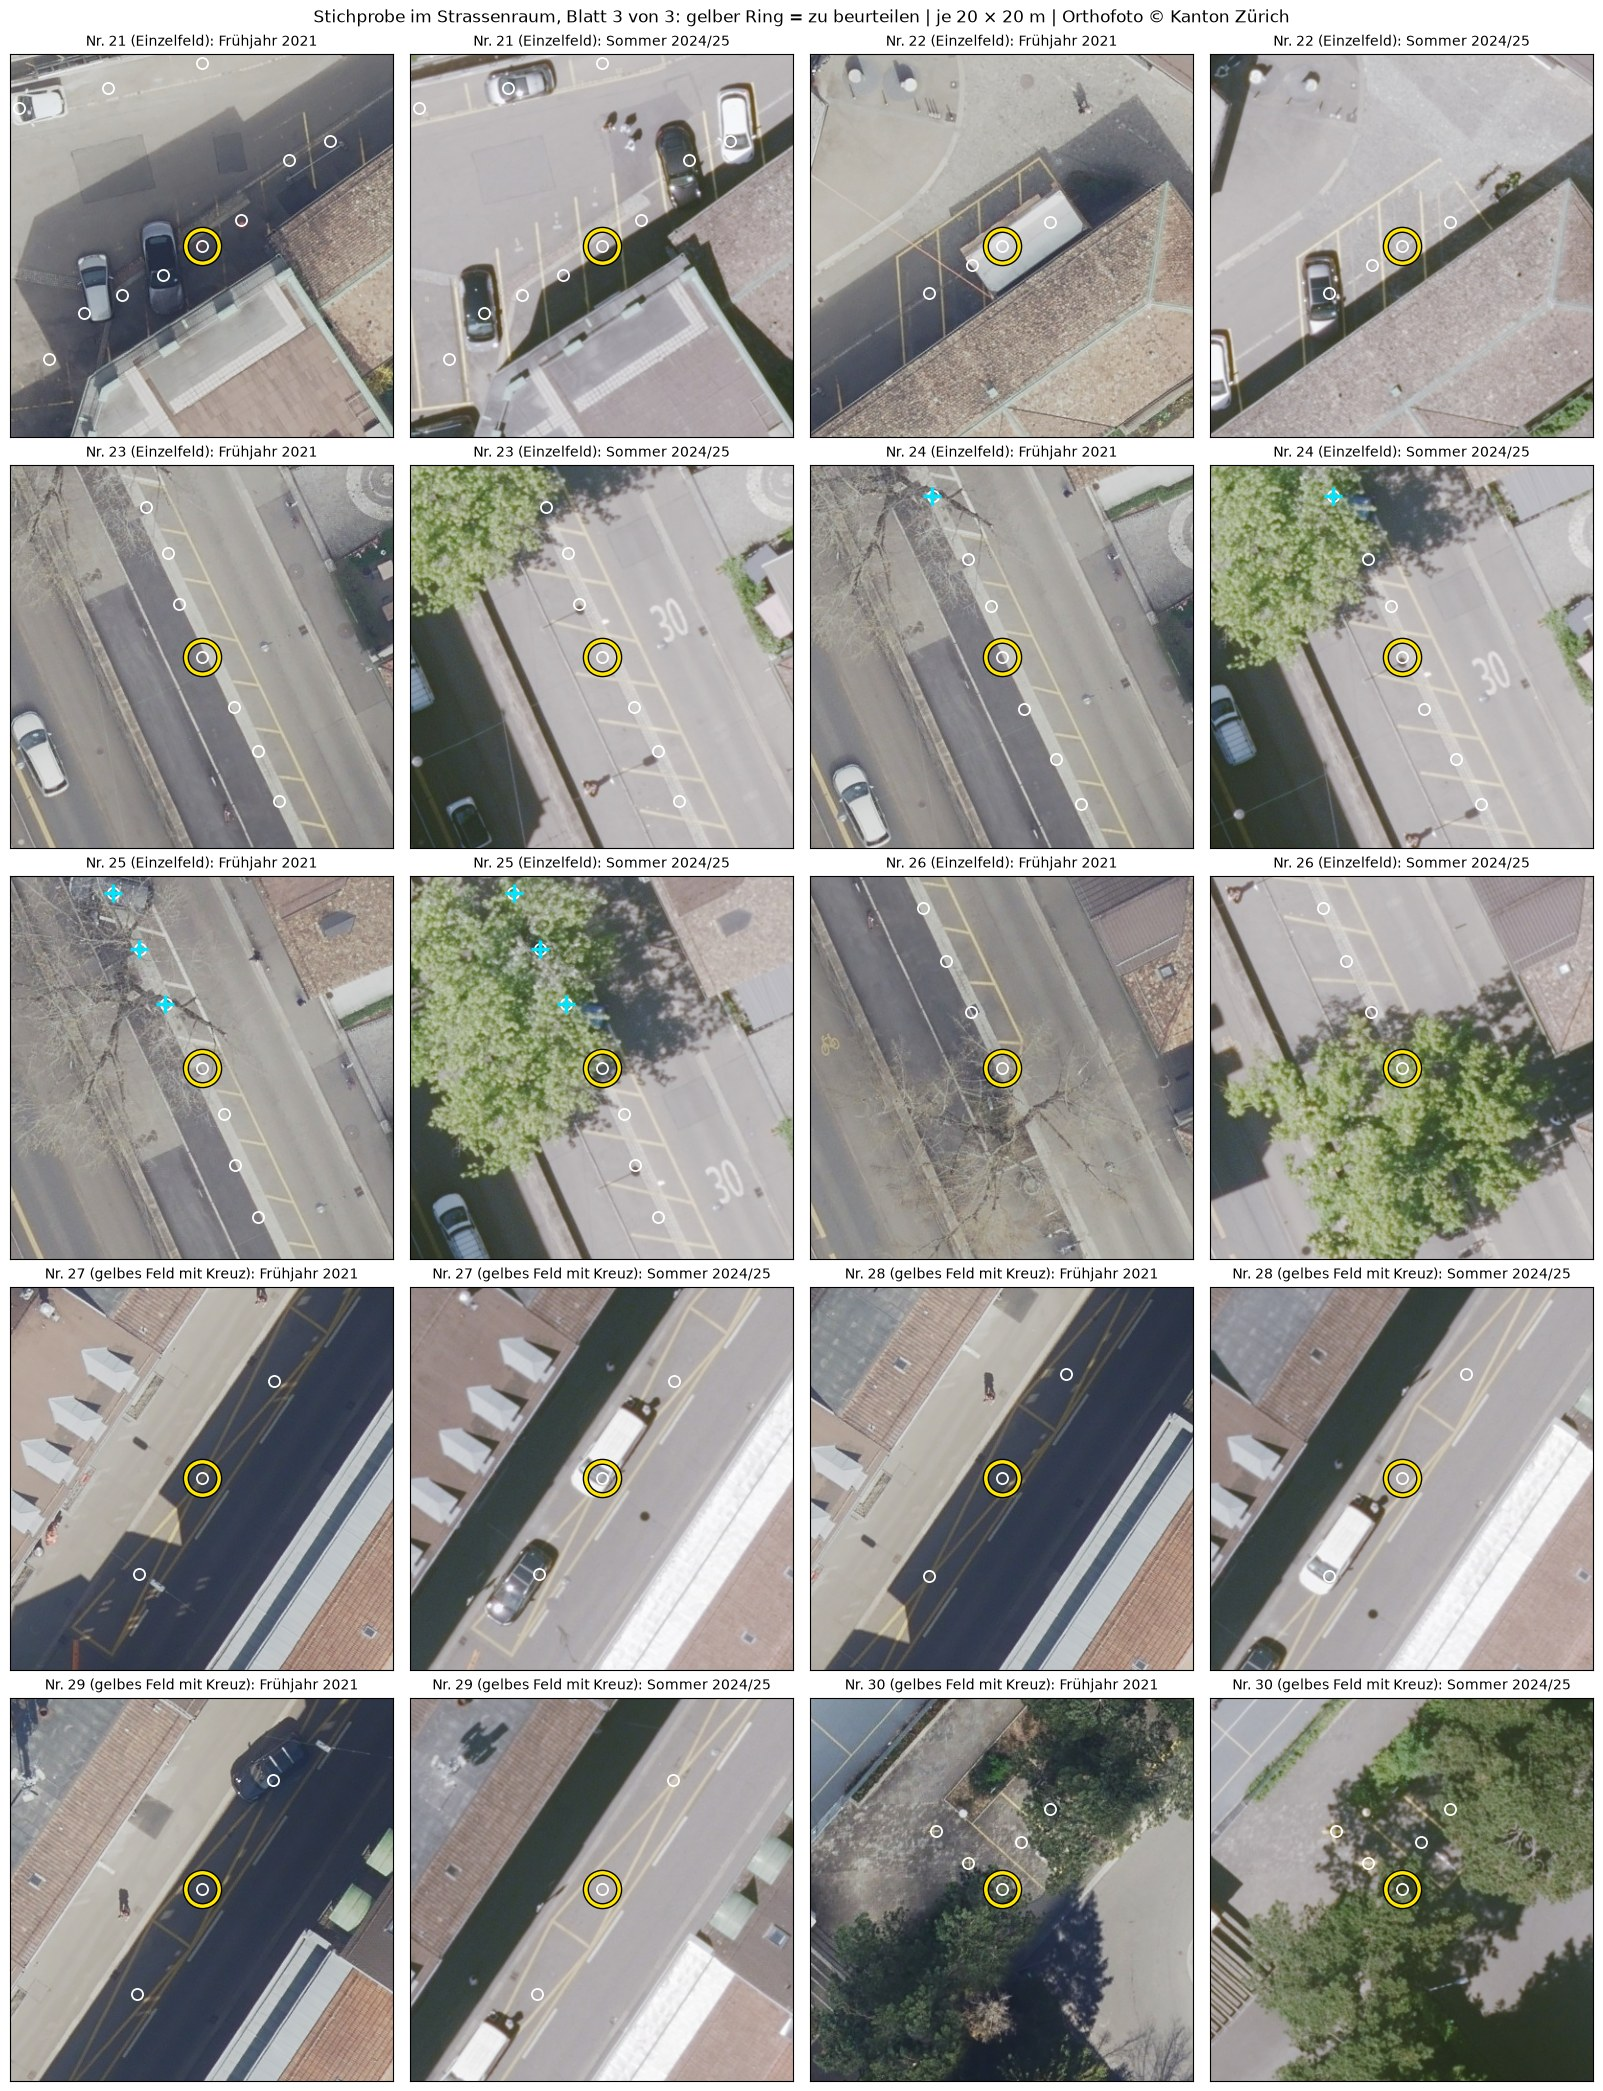

In [9]:
def zeige_blatt(blatt):
    # Ein Blatt mit 10 Feldern; je Feld links das Bild 2021 und rechts das Bild 2024/25
    teil = stichprobe.iloc[(blatt - 1) * 10: blatt * 10]
    fig, achsen = plt.subplots(5, 4, figsize=(16, 20.8), layout="constrained")
    for platz, feld in enumerate(teil.itertuples()):
        zeile, paar = divmod(platz, 2)                               # zwei Felder je Zeile
        for versatz, (versuch, angaben) in enumerate(VERSUCHE.items()):
            ax = achsen[zeile, 2 * paar + versatz]
            zeige_feld(ax, versuch, feld)
            ax.set_title(f"Nr. {feld.nr} ({feld.form}): {angaben['name']}", fontsize=10)
    fig.suptitle(f"Stichprobe im Strassenraum, Blatt {blatt} von 3: gelber Ring = zu beurteilen | je 20 × 20 m | Orthofoto © Kanton Zürich", fontsize=12)
    fig.savefig(ABB / f"stichprobe_strassenraum_{blatt}.jpg", dpi=100, bbox_inches="tight", pil_kwargs={"quality": 88})
    plt.show()

for blatt in [1, 2, 3]:
    zeige_blatt(blatt)

**Was die Abbildungen zeigen.** Jedes Feld der Stichprobe zweimal: im Bild von 2021 und im Bild von 2024/25. Der gelbe Ring liegt auf dem Feld. Weisse Ringe sind die übrigen gesetzten Felder, hellblaue Kreuze und Linien die amtlichen Objekte des jeweiligen Jahres. So sieht man, ob das Feld in einer Reihe mit amtlich geführten Feldern steht oder abseits davon.

## 4. Die Urteile

**Schritt 1: die Arten.** Sie stehen in `01b`, Abschnitt 11.2, N3. Sechs Arten standen fest, bevor gezogen wurde. Auf Rückfrage des Auftraggebers kam eine siebte dazu (`x`), und `b` und `c` wurden genauer gefasst. Das geschah, bevor ein Urteil eingetragen war.

| Kürzel | Art | woran man sie erkennt |
| --- | --- | --- |
| a | gewöhnliches Parkfeld | weiss oder blau markiert, für Autos |
| b | reserviertes oder privates Parkfeld | gelb markiert **ohne** Kreuz, oder auf einem Vorplatz, in einer Zufahrt, in einem Hof |
| c | Sonderfeld mit erkennbarer Nutzung | Aufschrift oder Zeichen: Taxi, Güterumschlag, Polizei, Invaliden, Car |
| x | gelbes Kreuz ohne erkennbare Nutzung | gelbes Feld mit Diagonalkreuz oder gelbe Linie mit Kreuz, ohne Aufschrift (Parkverbot) |
| d | Feld für Motorräder oder Velos | kleiner als ein Autofeld, oft mit Zweirad-Zeichen |
| e | kein Parkfeld in diesem Bild | an der Stelle ist kein Feld aufgemalt: noch nicht da, nicht mehr da oder irrtümlich gesetzt |
| f | nicht zu beurteilen | im Bild nicht zu erkennen |

**Warum `x` eine eigene Art ist.** Ein gelbes Feld mit Diagonalkreuz ist nach der Signalisationsverordnung ein Parkverbotsfeld, die gelbe Linie mit Kreuz eine Parkverbotslinie: Dort darf nicht parkiert werden. Trägt das Feld eine Aufschrift wie TAXI, ist es ein reserviertes Feld (dann `c`). Ohne Aufschrift lässt sich von oben nicht sagen, wozu das Feld dient.

**Schritt 2: eintragen.** Die Urteile stehen in `daten/ground_truth/stichprobe_strassenraum_urteil.csv`: eine Zeile je Feld und **je Bild eine Spalte** mit dem Kürzel (`urteil_2021`, `urteil_2024_25`). In `bemerkung` steht, was dem Auftraggeber auffiel. Die Datei lässt sich mit Excel öffnen (Trennzeichen `;`). Gibt es sie noch nicht, legt die Zelle eine leere Vorlage an. Eine vorhandene Datei wird **nie** überschrieben.

**Warum je Bild.** Eine Markierung kann sich zwischen 2021 und 2024/25 ändern: Ein Feld kommt dazu oder verschwindet. Das Kürzel sagt, was im jeweiligen Bild an der Stelle aufgemalt ist. Ist ein Feld nur verdeckt (Schatten, Baumkrone), bekommt es trotzdem das Kürzel seiner Art; dass es verdeckt ist, steht schon in der Ground Truth.

Die Zelle prüft auch, ob die Datei zu dieser Stichprobe gehört: Die Kennungen müssen übereinstimmen.

**Zum Vergleich** stehen in der Tabelle `kat_2021` und `kat_2024_25`: die Kategorie, die das Feld in der Ground Truth für das jeweilige Bild hat (Notebook 04). So sieht man, wo Urteil und Ground Truth nicht zusammenpassen, zum Beispiel ein Feld, das in der Ground Truth als `sichtbar` gilt und hier mit `d` oder `e` beurteilt ist.

In [10]:
ARTEN = {"a": "gewöhnliches Parkfeld (weiss oder blau)", "b": "reserviertes oder privates Parkfeld (gelb ohne Kreuz; Vorplatz, Zufahrt, Hof)",
         "c": "Sonderfeld mit erkennbarer Nutzung (Taxi, Güterumschlag, Polizei, Invaliden, Car)", "x": "gelbes Kreuz ohne erkennbare Nutzung (Parkverbot)",
         "d": "Feld für Motorräder oder Velos", "e": "kein Parkfeld in diesem Bild", "f": "nicht zu beurteilen"}
BILDER = {"urteil_2021": "Bild 2021", "urteil_2024_25": "Bild 2024/25"}       # je Bild eine Spalte mit dem Urteil

if not URTEILE.exists():                                             # Vorlage nur anlegen, wenn es die Datei noch nicht gibt
    stichprobe[["nr", "id", "form"]].assign(urteil_2021="", urteil_2024_25="", bemerkung="").to_csv(URTEILE, sep=";", index=False, encoding="utf-8-sig")
    print("Vorlage angelegt:", URTEILE.relative_to(ROOT).as_posix())

urteile = pd.read_csv(URTEILE, sep=";", encoding="utf-8-sig", dtype=str).fillna("")       # alles als Text lesen; leere Zellen bleiben leer
assert list(urteile.id) == list(stichprobe.id), "Die Datei der Urteile gehört nicht zu dieser Stichprobe."
for spalte in BILDER:
    urteile[spalte] = urteile[spalte].str.strip().str.lower()        # Leerzeichen weg, Kleinbuchstaben
    assert urteile[spalte].isin(list(ARTEN) + [""]).all(), f"In der Spalte {spalte} steht ein Kürzel, das es nicht gibt."
eingetragen = urteile[(urteile.urteil_2021 != "") & (urteile.urteil_2024_25 != "")]     # Maske: Felder mit Urteil für beide Bilder
print(f"Felder mit Urteil für beide Bilder: {len(eingetragen)} von {len(urteile)}")
neben = eingetragen.merge(stichprobe[["id", "kachel", "kat_2021", "kat_2024_25"]], on="id")          # Kategorie der Ground Truth je Bild daneben (Notebook 04)
neben[["nr", "form", "urteil_2021", "kat_2021", "urteil_2024_25", "kat_2024_25", "bemerkung"]].set_index("nr")

Felder mit Urteil für beide Bilder: 30 von 30


,form,urteil_2021,kat_2021,urteil_2024_25,kat_2024_25,bemerkung
nr,,,,,,
1,gelbes Feld mit Kreuz,x,sichtbar,x,sichtbar,
2,gelbes Feld mit Kreuz,x,einzeln,x,einzeln,
3,unklar,b,"verdeckt, belegt",b,sichtbar,"Privatparkplatz, kein Invalidenfeld erkennbar ..."
4,Einzelfeld,d,kein Parkfeld,d,sichtbar,"Velofeld (bestätigt); 2024/25 sichtbar, wegen ..."
5,Einzelfeld,b,sichtbar,b,sichtbar,gelbes Parkfeld
6,Einzelfeld,b,sichtbar,b,sichtbar,gelbes Parkfeld
7,Einzelfeld,b,sichtbar,b,sichtbar,gelbes Parkfeld
8,Einzelfeld,b,sichtbar,b,sichtbar,gelbes Parkfeld
9,gelbes Feld mit Kreuz,x,einzeln,e,kein Parkfeld,2024/25 kein Parkfeld


**Schritt 3: auszählen.** Sobald Urteile eingetragen sind, zählt die Zelle sie je Art und je Bild. Dazu nennt sie die Felder, bei denen sich das Urteil zwischen den Bildern unterscheidet.

Vorher: eine Zeile je Feld → nachher: Anzahl je Art, einmal für das Bild 2021 und einmal für das Bild 2024/25.

In [11]:
if len(eingetragen) > 0:
    anzahl = pd.DataFrame({name: eingetragen[spalte].value_counts().reindex(list(ARTEN), fill_value=0) for spalte, name in BILDER.items()})   # jede Art, auch mit 0
    anzahl.insert(0, "Art", pd.Series(ARTEN))                        # Beschreibung der Art neben das Kürzel
    display(anzahl)
    verschieden = eingetragen[eingetragen.urteil_2021 != eingetragen.urteil_2024_25]     # Maske: Urteil je Bild verschieden
    print(f"Bei {len(verschieden)} von {len(eingetragen)} Feldern unterscheidet sich das Urteil zwischen den Bildern (Nr. {', '.join(verschieden.nr)}).")
else:
    print("Noch keine Urteile eingetragen. Die Auszählung erscheint, sobald die Spalten mit den Urteilen ausgefüllt sind.")

,Art,Bild 2021,Bild 2024/25
a,gewöhnliches Parkfeld (weiss oder blau),3,3
b,reserviertes oder privates Parkfeld (gelb ohne...,13,13
c,"Sonderfeld mit erkennbarer Nutzung (Taxi, Güte...",1,0
x,gelbes Kreuz ohne erkennbare Nutzung (Parkverbot),10,10
d,Feld für Motorräder oder Velos,1,1
e,kein Parkfeld in diesem Bild,2,3
f,nicht zu beurteilen,0,0


Bei 3 von 30 Feldern unterscheidet sich das Urteil zwischen den Bildern (Nr. 9, 10, 13).


**Wie man das Ergebnis liest.** Die Anteile gelten für die Felder, aus denen gezogen wurde (Abschnitt 1, Schritt 3), nicht für alle Felder der Ground Truth. Mit 30 Feldern sind sie grob: Bei einem Anteil von der Hälfte reicht das 95-%-Intervall etwa von einem Drittel bis zu zwei Dritteln.

**Schritt 4: die Auszählung in Sätzen.** Drei Gruppen: gewöhnliche Parkfelder (`a`), reservierte, private oder gesperrte Felder (`b` und `x`) und alles andere. Dazu die Zahl der Ausschnitte, in denen die Felder liegen: Felder derselben Reihe sind keine unabhängigen Fälle.

In [12]:
if len(eingetragen) > 0:
    for spalte, name in BILDER.items():
        urteil = eingetragen[spalte]
        print(f"{name}: {int((urteil == 'a').sum())} von {len(eingetragen)} gewöhnliche Parkfelder | {int(urteil.isin(['b', 'x']).sum())} reservierte, private oder gesperrte Felder "
              f"(davon {int((urteil == 'b').sum())} reserviert oder privat, {int((urteil == 'x').sum())} mit gelbem Kreuz) | {int(urteil.isin(['c', 'd', 'e', 'f']).sum())} anderes")
    gelb = int(((eingetragen.urteil_2021 == 'b') & eingetragen.bemerkung.str.contains('gelb')).sum())    # Felder der Art b, die als gelb beschrieben sind
    print(f"Von den Feldern der Art b (Bild 2021) hat der Auftraggeber {gelb} als gelb markiert beschrieben (Spalte bemerkung).")
    print(f"Die {len(eingetragen)} beurteilten Felder liegen in {neben.kachel.nunique()} Ausschnitten.")

Bild 2021: 3 von 30 gewöhnliche Parkfelder | 23 reservierte, private oder gesperrte Felder (davon 13 reserviert oder privat, 10 mit gelbem Kreuz) | 4 anderes
Bild 2024/25: 3 von 30 gewöhnliche Parkfelder | 23 reservierte, private oder gesperrte Felder (davon 13 reserviert oder privat, 10 mit gelbem Kreuz) | 4 anderes
Von den Feldern der Art b (Bild 2021) hat der Auftraggeber 12 als gelb markiert beschrieben (Spalte bemerkung).
Die 30 beurteilten Felder liegen in 19 Ausschnitten.


**Was die Auszählung zeigt** (Urteile vom 27.11.2026, alle 30 Felder). Nur wenige der gezogenen Felder sind gewöhnliche Parkfelder. Die meisten sind reservierte oder private Felder (`b`, fast alle gelb markiert) und Felder oder Linien mit gelbem Kreuz, auf denen nicht parkiert werden darf (`x`).

**Was das für Teil 3 des Deltas heisst.** Teil 3 sagt: Die Ground Truth hat im Strassenraum mehr Felder als die amtlichen Daten (Notebook 10, Abschnitt 6). Die Stichprobe spricht dafür, dass dieser Überschuss vor allem aus gelben Markierungen besteht und nicht aus öffentlichen Parkplätzen, die in den amtlichen Daten fehlen. Zwei Folgen:
- Regel B (`01b`, Abschnitt 11, E2) trennt öffentlich und privat nicht vollständig: Gelbe, reservierte Felder im Strassenraum gelten als öffentlich.
- Felder mit gelbem Kreuz zählen in der Ground Truth und in der Methode als Parkplätze mit (`01b`, 8.5 D4), auch dort, wo die amtlichen Daten sie nicht führen.

**Grenzen dieser Aussage.**

| Grenze | Folge |
| --- | --- |
| **Nicht dieselben Felder wie in Teil 3.** | Gezogen wurde aus den Feldern von Abschnitt 1 im ganzen Gebiet. Teil 3 wird nur in den Testblöcken gerechnet und ist ein Saldo: Felder, die nur die Ground Truth hat, minus Felder, die nur die amtlichen Daten haben. |
| **Wenige Felder, zum Teil in derselben Reihe.** | Die Anteile sind grob. Felder derselben Reihe sind meist von derselben Art; die Stichprobe wiegt darum weniger als 30 unabhängige Fälle. |
| **Art aus dem Luftbild.** | Ob ein gelbes Feld privat ist oder einer Gruppe vorbehalten, und ob ein Feld rechtlich öffentlich ist, sieht man von oben nicht. |
| **Urteile nach Diktat.** | Der Auftraggeber hat die Urteile diktiert; eingetragen wurden sie für ihn. Unklare Lesarten hat er danach bestätigt und dabei zwei Urteile geändert (Nr. 3 und Nr. 30; siehe `bemerkung`). Zwei Durchgänge desselben Menschen stimmen also nicht in jedem Feld überein. |
| **Wo ein Feld verdeckt ist.** | Ist ein Feld in einem Bild ganz verdeckt, steht dort die Art aus dem anderen Bild (siehe `bemerkung`). |

## Was wir gesehen haben

- Wie viele neu gesetzte Felder im Strassenraum kein amtliches Objekt in 3 m haben, steht in Abschnitt 1; ein Teil davon sind Streifen und bleibt weg.
- 30 davon sind gezogen und in beiden Bildern gezeigt (Abschnitt 3).
- Ob Urteile vorliegen und wie sie sich verteilen, steht in Abschnitt 4.

## Wie es weitergeht

Was aus dem Befund folgt, entscheidet der Auftraggeber (`01b`, Abschnitt 11.2, Folgefrage zu N3). Die Leseregel, die vor dem Urteilen feststand: Sind es vor allem gewöhnliche Felder (`a`), spricht das für Lücken in den amtlichen Daten oder für neue Felder. Sind es vor allem reservierte oder private Felder (`b`), lässt Regel B Felder durch, die nicht öffentlich sind. Felder mit gelbem Kreuz ohne Nutzung (`x`) und Felder für Zweiräder (`d`) sind keine Parkplätze für Autos; sie wären aus der Zahl herauszurechnen.